# CNN Exercises: Earlier Notebook Variant

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Academic coursework · date not explicitly confirmed  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Preserve a separately submitted notebook variant for image classification practical work.

**Approach:** Keras CNN exercises and associated report copied without modifications.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


# Exercice 1

In [17]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from keras.regularizers import l2

# Initializing the CNN
classifier = Sequential()

# Step 1 - Convolution + Regularization
classifier.add(Conv2D(32, (3, 3), input_shape=(64, 64, 3), activation='relu', kernel_regularizer=l2(0.01)))

# Step 2 - Pooling
classifier.add(MaxPooling2D(pool_size=(2, 2)))

# Adding a second convolutional layer with regularization
classifier.add(Conv2D(64, (3, 3), activation='relu', kernel_regularizer=l2(0.01)))
classifier.add(MaxPooling2D(pool_size=(2, 2)))

# Adding a third convolutional layer with dropout
classifier.add(Conv2D(128, (3, 3), activation='relu', kernel_regularizer=l2(0.01)))
classifier.add(MaxPooling2D(pool_size=(2, 2)))
classifier.add(Dropout(0.5))  # Dropout regularization

# Flattening
classifier.add(Flatten())

# Fully connected layers with dropout
classifier.add(Dense(units=128, activation='relu', kernel_regularizer=l2(0.01)))
classifier.add(Dropout(0.5))  # Dropout regularization
classifier.add(Dense(units=1, activation='sigmoid'))

# Compiling the CNN
classifier.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])


In [21]:

# # Part 2 - Fitting the CNN to the images
from keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator (rescale = 1./255,
shear_range = 0.2,
zoom_range = 0.2,
horizontal_flip = True)

test_datagen = ImageDataGenerator (rescale = 1. /255)

training_set = train_datagen. flow_from_directory('CATS-DOGS/training_set',
target_size = (64, 64) ,
batch_size = 32,
class_mode = 'binary')

test_set = test_datagen. flow_from_directory ('CATS-DOGS/test_set',
target_size = (64, 64),
batch_size = 64,
class_mode = 'binary')
batch_size = 64  
# In the tensorflow 2 and upper "fit_generator" is deprecated and replaced by "fit"
history = classifier.fit(training_set,
steps_per_epoch = 8000/batch_size,
epochs = 50,
validation_data = test_set,
validation_steps = 2000/batch_size)

Found 8000 images belonging to 2 classes.
Found 2000 images belonging to 2 classes.
Epoch 1/50
125/125 [==============================] - 18s 143ms/step - loss: 0.6932 - accuracy: 0.4997 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 2/50
125/125 [==============================] - 18s 140ms/step - loss: 0.6932 - accuracy: 0.4950 - val_loss: 0.6931 - val_accuracy: 0.5000
Epoch 3/50
125/125 [==============================] - 18s 145ms/step - loss: 0.6931 - accuracy: 0.5088 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 4/50
125/125 [==============================] - 18s 141ms/step - loss: 0.6932 - accuracy: 0.5027 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 5/50
125/125 [==============================] - 17s 139ms/step - loss: 0.6932 - accuracy: 0.5015 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 6/50
125/125 [==============================] - 17s 137ms/step - loss: 0.6932 - accuracy: 0.5020 - val_loss: 0.6932 - val_accuracy: 0.5000
Epoch 7/50
125/125 [==========================

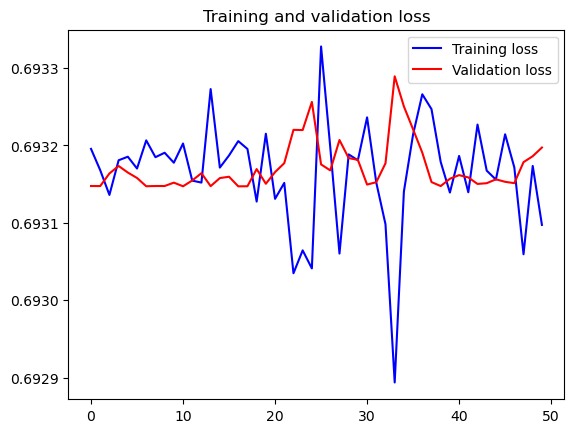

In [22]:
# # Part 3 - Plotting the tarining and validation loss
import matplotlib.pyplot as plt

loss = history.history ['loss']
val_loss = history. history ['val_loss']

epochs = range(len(loss) )

plt. figure ()

plt.plot (epochs, loss, 'b', label='Training loss')
plt.plot (epochs, val_loss, 'r', label='Validation loss')
plt.title ('Training and validation loss')
plt. legend ()

plt. show ()

# # Part 4 - Making new predictions
import numpy as np
from keras.preprocessing import image

test_image = image. load_img('CATS-DOGS/single_prediction/cat_or_dog_1.jpg', target_size
= (64, 64))

In [23]:
# Part 4 - Making new predictions
import numpy as np
from keras.preprocessing import image

# Prediction for first image
img_path1 = 'CATS-DOGS/single_prediction/cat_or_dog_1.jpg'
test_image1 = image.load_img(img_path1, target_size=(64, 64))  # Reload the image
test_image1 = image.img_to_array(test_image1)  # Convert to array
test_image1 = np.expand_dims(test_image1, axis=0)  # Add batch dimension

result1 = classifier.predict(test_image1)
if result1[0][0] == 1:
    prediction1 = 'dog'
else:
    prediction1 = 'cat'

print(f"The first image is a {prediction1}")

# Prediction for second image
img_path2 = 'CATS-DOGS/single_prediction/cat_or_dog_2.jpg'
test_image2 = image.load_img(img_path2, target_size=(64, 64))  # Reload the image
test_image2 = image.img_to_array(test_image2)  # Convert to array
test_image2 = np.expand_dims(test_image2, axis=0)  # Add batch dimension

result2 = classifier.predict(test_image2)
if result2[0][0] == 1:
    prediction2 = 'dog'
else:
    prediction2 = 'cat'

print(f"The second image is a {prediction2}")


1/1 [==============================] - 0s 16ms/step
The first image is a cat
1/1 [==============================] - 0s 16ms/step
The second image is a cat


# Exercice 2

In [24]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist

# Load the Fashion-MNIST data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize pixel values to range [0, 1]
x_train = x_train / 255.0
x_test = x_test / 255.0

# Add a channel dimension for CNN compatibility
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

# One-hot encode labels
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)


In [25]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# Define the CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Summary of the model
model.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_5 (Conv2D)           (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d_5 (MaxPoolin  (None, 13, 13, 32)        0         
 g2D)                                                            
                                                                 
 conv2d_6 (Conv2D)           (None, 11, 11, 64)        18496     
                                                                 
 max_pooling2d_6 (MaxPoolin  (None, 5, 5, 64)          0         
 g2D)                                                            
                                                                 
 flatten_2 (Flatten)         (None, 1600)              0         
                                                                 
 dense_6 (Dense)             (None, 128)              

In [26]:
# Train the model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_test, y_test)
)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_accuracy:.4f}")


Epoch 1/10
938/938 [==============================] - 15s 16ms/step - loss: 0.4868 - accuracy: 0.8239 - val_loss: 0.3846 - val_accuracy: 0.8649
Epoch 2/10
938/938 [==============================] - 15s 16ms/step - loss: 0.3263 - accuracy: 0.8816 - val_loss: 0.3479 - val_accuracy: 0.8744
Epoch 3/10
938/938 [==============================] - 16s 17ms/step - loss: 0.2797 - accuracy: 0.8972 - val_loss: 0.2903 - val_accuracy: 0.8955
Epoch 4/10
938/938 [==============================] - 15s 16ms/step - loss: 0.2492 - accuracy: 0.9080 - val_loss: 0.2805 - val_accuracy: 0.8997
Epoch 5/10
938/938 [==============================] - 15s 16ms/step - loss: 0.2249 - accuracy: 0.9164 - val_loss: 0.2657 - val_accuracy: 0.9043
Epoch 6/10
938/938 [==============================] - 15s 16ms/step - loss: 0.2012 - accuracy: 0.9244 - val_loss: 0.2641 - val_accuracy: 0.9039
Epoch 7/10
938/938 [==============================] - 15s 16ms/step - loss: 0.1816 - accuracy: 0.9315 - val_loss: 0.2807 - val_accuracy:

### Steps 2 Improvment

In [27]:
from tensorflow.keras.regularizers import l2
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define the improved CNN model
improved_model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1), kernel_regularizer=l2(0.01)),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Conv2D(64, (3, 3), activation='relu', kernel_regularizer=l2(0.01)),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    Flatten(),
    Dense(256, activation='relu', kernel_regularizer=l2(0.01)),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

# Compile the improved model
improved_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Data augmentation
datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=False
)

# Fit the improved model
history_improved = improved_model.fit(
    datagen.flow(x_train, y_train, batch_size=64),
    epochs=20,
    validation_data=(x_test, y_test)
)

# Evaluate the improved model
test_loss_improved, test_accuracy_improved = improved_model.evaluate(x_test, y_test)
print(f"Improved Test Accuracy: {test_accuracy_improved:.4f}")


Epoch 1/20
938/938 [==============================] - 23s 23ms/step - loss: 1.3870 - accuracy: 0.6519 - val_loss: 0.9152 - val_accuracy: 0.7493
Epoch 2/20
938/938 [==============================] - 23s 24ms/step - loss: 1.0241 - accuracy: 0.7086 - val_loss: 0.8630 - val_accuracy: 0.7597
Epoch 3/20
938/938 [==============================] - 23s 24ms/step - loss: 0.9888 - accuracy: 0.7137 - val_loss: 0.8161 - val_accuracy: 0.7715
Epoch 4/20
938/938 [==============================] - 23s 24ms/step - loss: 0.9614 - accuracy: 0.7199 - val_loss: 0.8137 - val_accuracy: 0.7678
Epoch 5/20
938/938 [==============================] - 23s 24ms/step - loss: 0.9413 - accuracy: 0.7257 - val_loss: 0.7982 - val_accuracy: 0.7658
Epoch 6/20
938/938 [==============================] - 22s 24ms/step - loss: 0.9309 - accuracy: 0.7268 - val_loss: 0.8227 - val_accuracy: 0.7556
Epoch 7/20
938/938 [==============================] - 22s 23ms/step - loss: 0.9177 - accuracy: 0.7291 - val_loss: 0.8020 - val_accuracy: